<a href="https://colab.research.google.com/github/arnavpatil427gh/Telecom-customer-churn-prediction/blob/main/notebooks/01_tc_churn_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telecom Customer Churn Prediction

####1. Data Preprocessing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/telecom_churn.csv')
df.head()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   customer_id           243553 non-null  int64 
 1   telecom_partner       243553 non-null  object
 2   gender                243553 non-null  object
 3   age                   243553 non-null  int64 
 4   state                 243553 non-null  object
 5   city                  243553 non-null  object
 6   pincode               243553 non-null  int64 
 7   date_of_registration  243553 non-null  object
 8   num_dependents        243553 non-null  int64 
 9   estimated_salary      243553 non-null  int64 
 10  calls_made            243553 non-null  int64 
 11  sms_sent              243553 non-null  int64 
 12  data_used             243553 non-null  int64 
 13  churn                 243553 non-null  int64 
dtypes: int64(9), object(5)
memory usage: 26.0+ MB


In [ ]:
print("Missing values per column: \n")
print(df.isnull().sum())

Missing values per column: 

customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["churn"].value_counts(normalize=True))

print("\nNumeric feature summary by churn:")
print(
    df.groupby("churn")
      .mean(numeric_only=True)
      .T
      .assign(
          difference=lambda x: x[1] - x[0]
      )
      .sort_values("difference", key=abs, ascending=False)
      .head(15)
)

Dataset shape: (243553, 17)

Columns:
['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city', 'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn', 'age_group', 'salary_band', 'tenure']

Target distribution:
churn
0    0.799522
1    0.200478
Name: proportion, dtype: float64

Numeric feature summary by churn:
churn                         0              1  difference
pincode           549368.716335  550029.907367  661.191032
estimated_salary   85083.726934   84771.527495 -312.199439
customer_id       121718.955163  122008.487476  289.532314
data_used           5000.235757    5005.817642    5.581885
tenure              1884.290875    1882.839945   -1.450930
calls_made            49.094178      49.223585    0.129407
sms_sent              24.038336      23.925697   -0.112639
age                   46.070699      46.105167    0.034468
num_dependents         1.999302       1.990313   -0.008989


In [ ]:
df['date_of_registration'] = pd.to_datetime(df['date_of_registration'])
print(df['date_of_registration'].dtype)

datetime64[ns]


In [ ]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

if "churn" in num_cols:
  num_cols.remove("churn")

print("Numerical features:")
print(num_cols)

print("\nCategorical features:")
print(cat_cols)

Numerical features:
['customer_id', 'age', 'pincode', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used']

Categorical features:
['telecom_partner', 'gender', 'state', 'city']


In [ ]:
neg_calls = (df['calls_made'] < 0).sum()
neg_sms = (df['sms_sent'] < 0).sum()
neg_data = (df['data_used'] < 0).sum()

print("Total negative calls made:", neg_calls)
print("Total negative sms sent:", neg_sms)
print("Total negative data used:", neg_data)

Total negative calls made: 6713
Total negative sms sent: 7375
Total negative data used: 6050


In [ ]:
df['calls_made'] = df['calls_made'].apply(lambda x: max(x,0))
df['sms_sent'] = df['sms_sent'].apply(lambda x: max(x,0))
df['data_used'] = df['data_used'].apply(lambda x: max(x,0))

neg_calls = (df['calls_made'] < 0).sum()
neg_sms = (df['sms_sent'] < 0).sum()
neg_data = (df['data_used'] < 0).sum()

print("Total negative calls made:", neg_calls)
print("Total negative sms sent:", neg_sms)
print("Total negative data used:", neg_data)

Total negative calls made: 0
Total negative sms sent: 0
Total negative data used: 0


####2. Exploratory Data Analysis (EDA)

In [ ]:
print(df['churn'].value_counts())

print("\nChurn percentage:")
print(df['churn'].value_counts(normalize=True) *100)

churn
0    194726
1     48827
Name: count, dtype: int64

Churn percentage:
churn
0    79.952208
1    20.047792
Name: proportion, dtype: float64


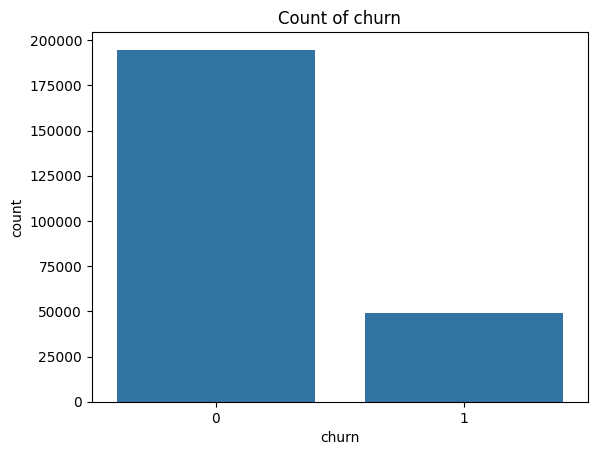

In [ ]:
sns.countplot(x="churn", data=df)
plt.title("Count of churn")
plt.show()

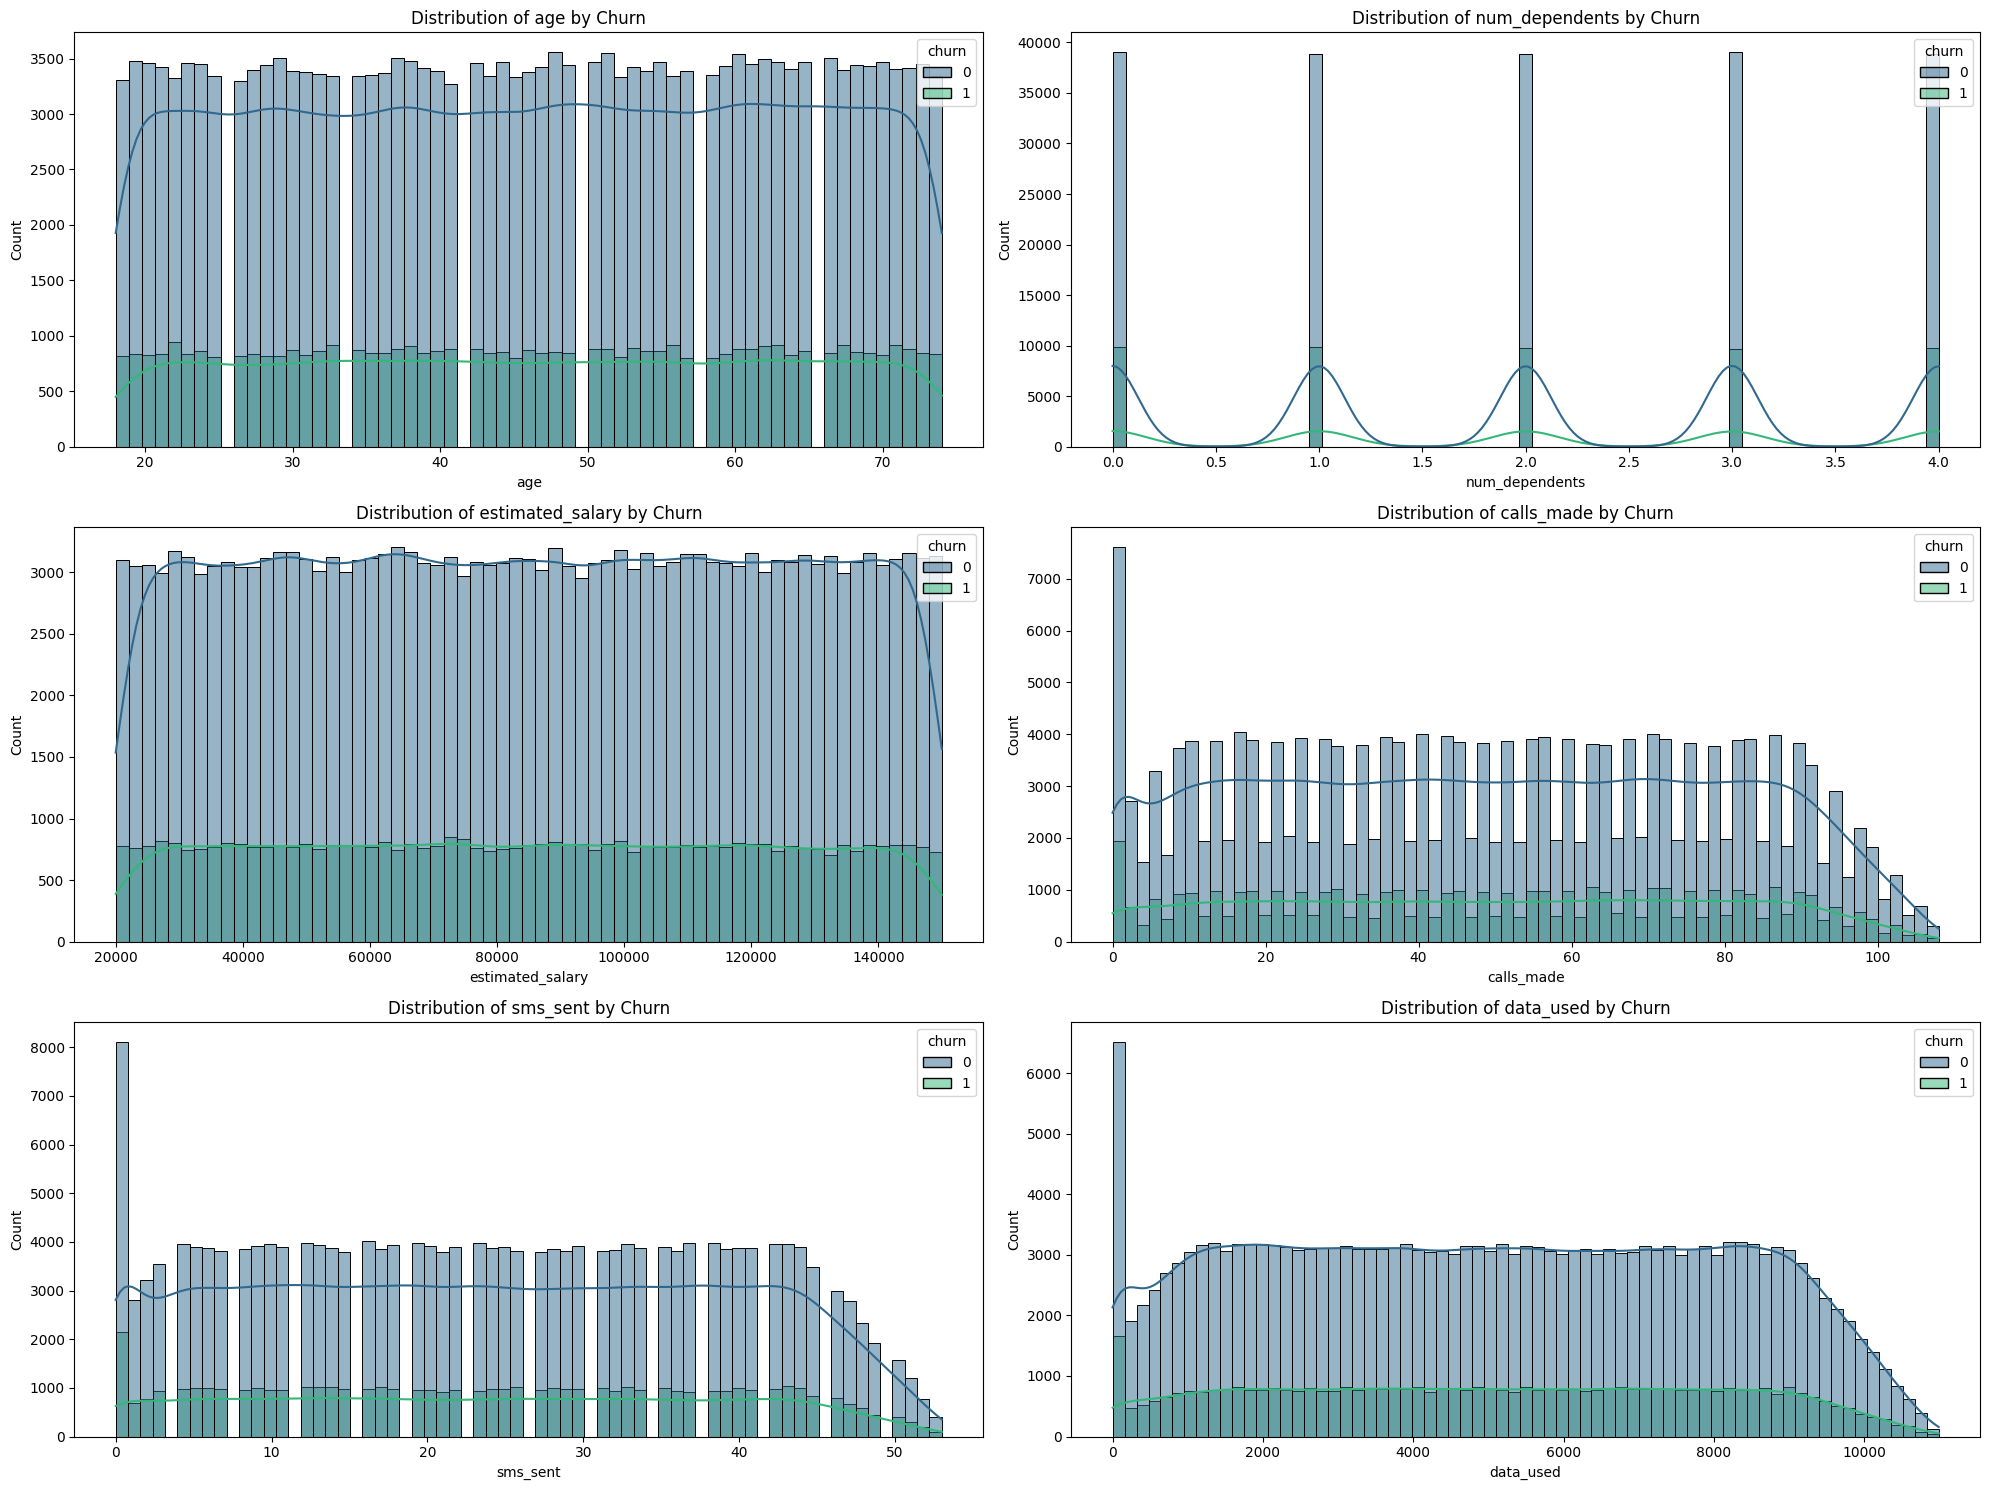

In [ ]:
numerical_cols = ['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used']

plt.figure(figsize=(20, 15))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 2, i + 1) # Adjust subplot grid as needed
    sns.histplot(data=df, x=col, hue='churn', kde=True, palette='viridis')
    plt.title(f'Distribution of {col} by Churn')
    plt.xlabel(col)
    plt.ylabel('Count')
plt.tight_layout()
plt.show()

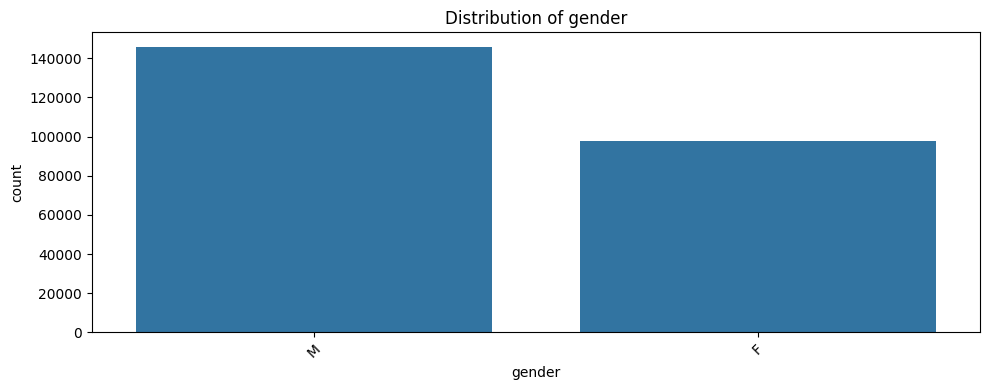

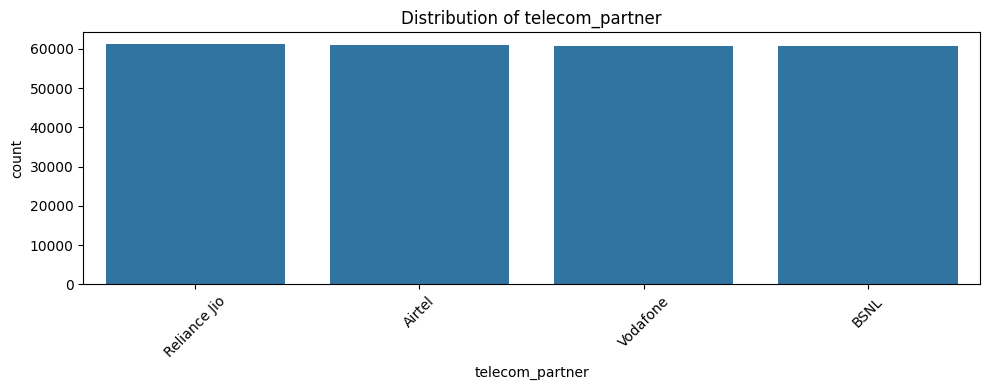

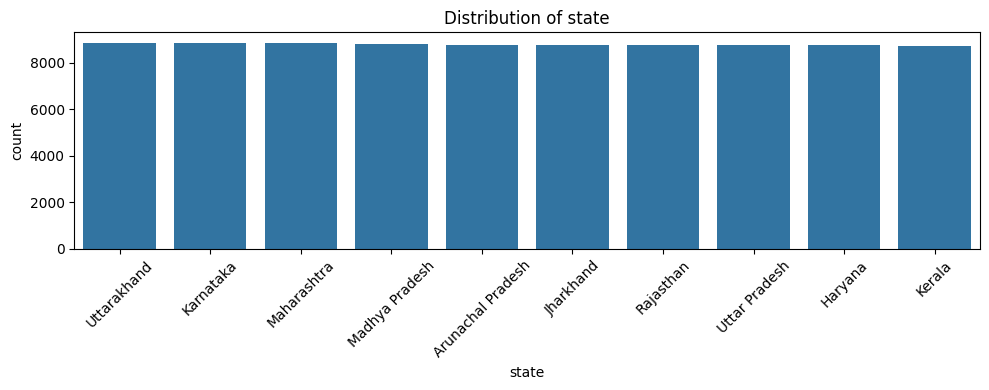

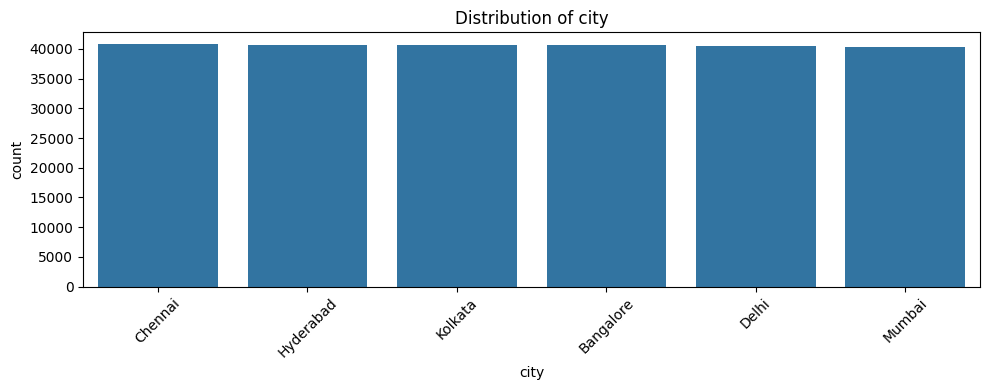

In [ ]:
categorical_cols = ["gender", "telecom_partner", "state", "city"]

for col in categorical_cols:
    plt.figure(figsize=(10, 4))

    top_categories = df[col].value_counts().index[:10]

    sns.countplot(
        data=df,
        x=col,
        order=top_categories
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
age_bins = [18, 25, 35, 45, 55, 65]
age_labels = ["18–25", "26–35", "36–45", "46–55", "56–65"]

df["age_group"] = pd.cut(
    x=df["age"],
    bins=age_bins,
    labels=age_labels
)

print(df["age_group"].value_counts().sort_index())


age_group
18–25    29898
26–35    42302
36–45    42649
46–55    43005
56–65    42953
Name: count, dtype: int64


In [ ]:
salary_labels = ["Low", "Medium", "High", "Very High"]

df["salary_band"] = pd.qcut(
    x=df["estimated_salary"],
    q=4,
    labels=salary_labels
)

print(df["salary_band"].value_counts().sort_index())

salary_band
Low          60892
Medium       60885
High         60889
Very High    60887
Name: count, dtype: int64


In [ ]:
state_distribution = (
    df["state"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
    .reset_index()
)

state_distribution.columns = ["State", "Percentage (%)"]

# Displaying state_distribution with the State column left-aligned
style_df = state_distribution.style.set_properties(**{'text-align': 'left'}, subset=['State']).hide(axis='index')
style_df

State,Percentage (%)
Uttarakhand,3.640000
Karnataka,3.630000
Maharashtra,3.620000
Madhya Pradesh,3.620000
Arunachal Pradesh,3.600000
Jharkhand,3.590000
Rajasthan,3.590000
Uttar Pradesh,3.590000
Haryana,3.590000
Kerala,3.580000


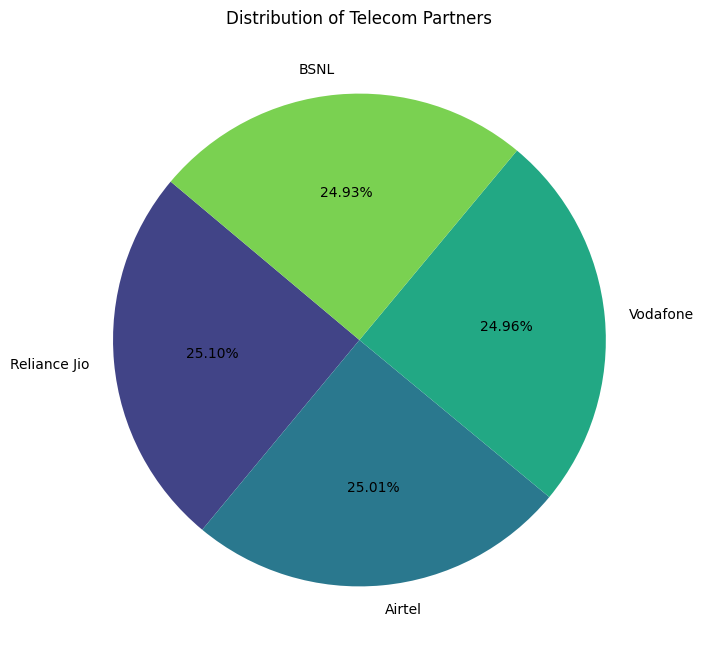

In [ ]:
partner_distribution = (
    df["telecom_partner"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

partner_distribution.columns = ["Telecom Partner", "Percentage (%)"]

# Visualize the distribution using a pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    partner_distribution["Percentage (%)"],
    labels=partner_distribution["Telecom Partner"],
    autopct='%1.2f%%',
    startangle=140,
    colors=sns.color_palette('viridis', len(partner_distribution))
)
plt.title("Distribution of Telecom Partners")
plt.show()

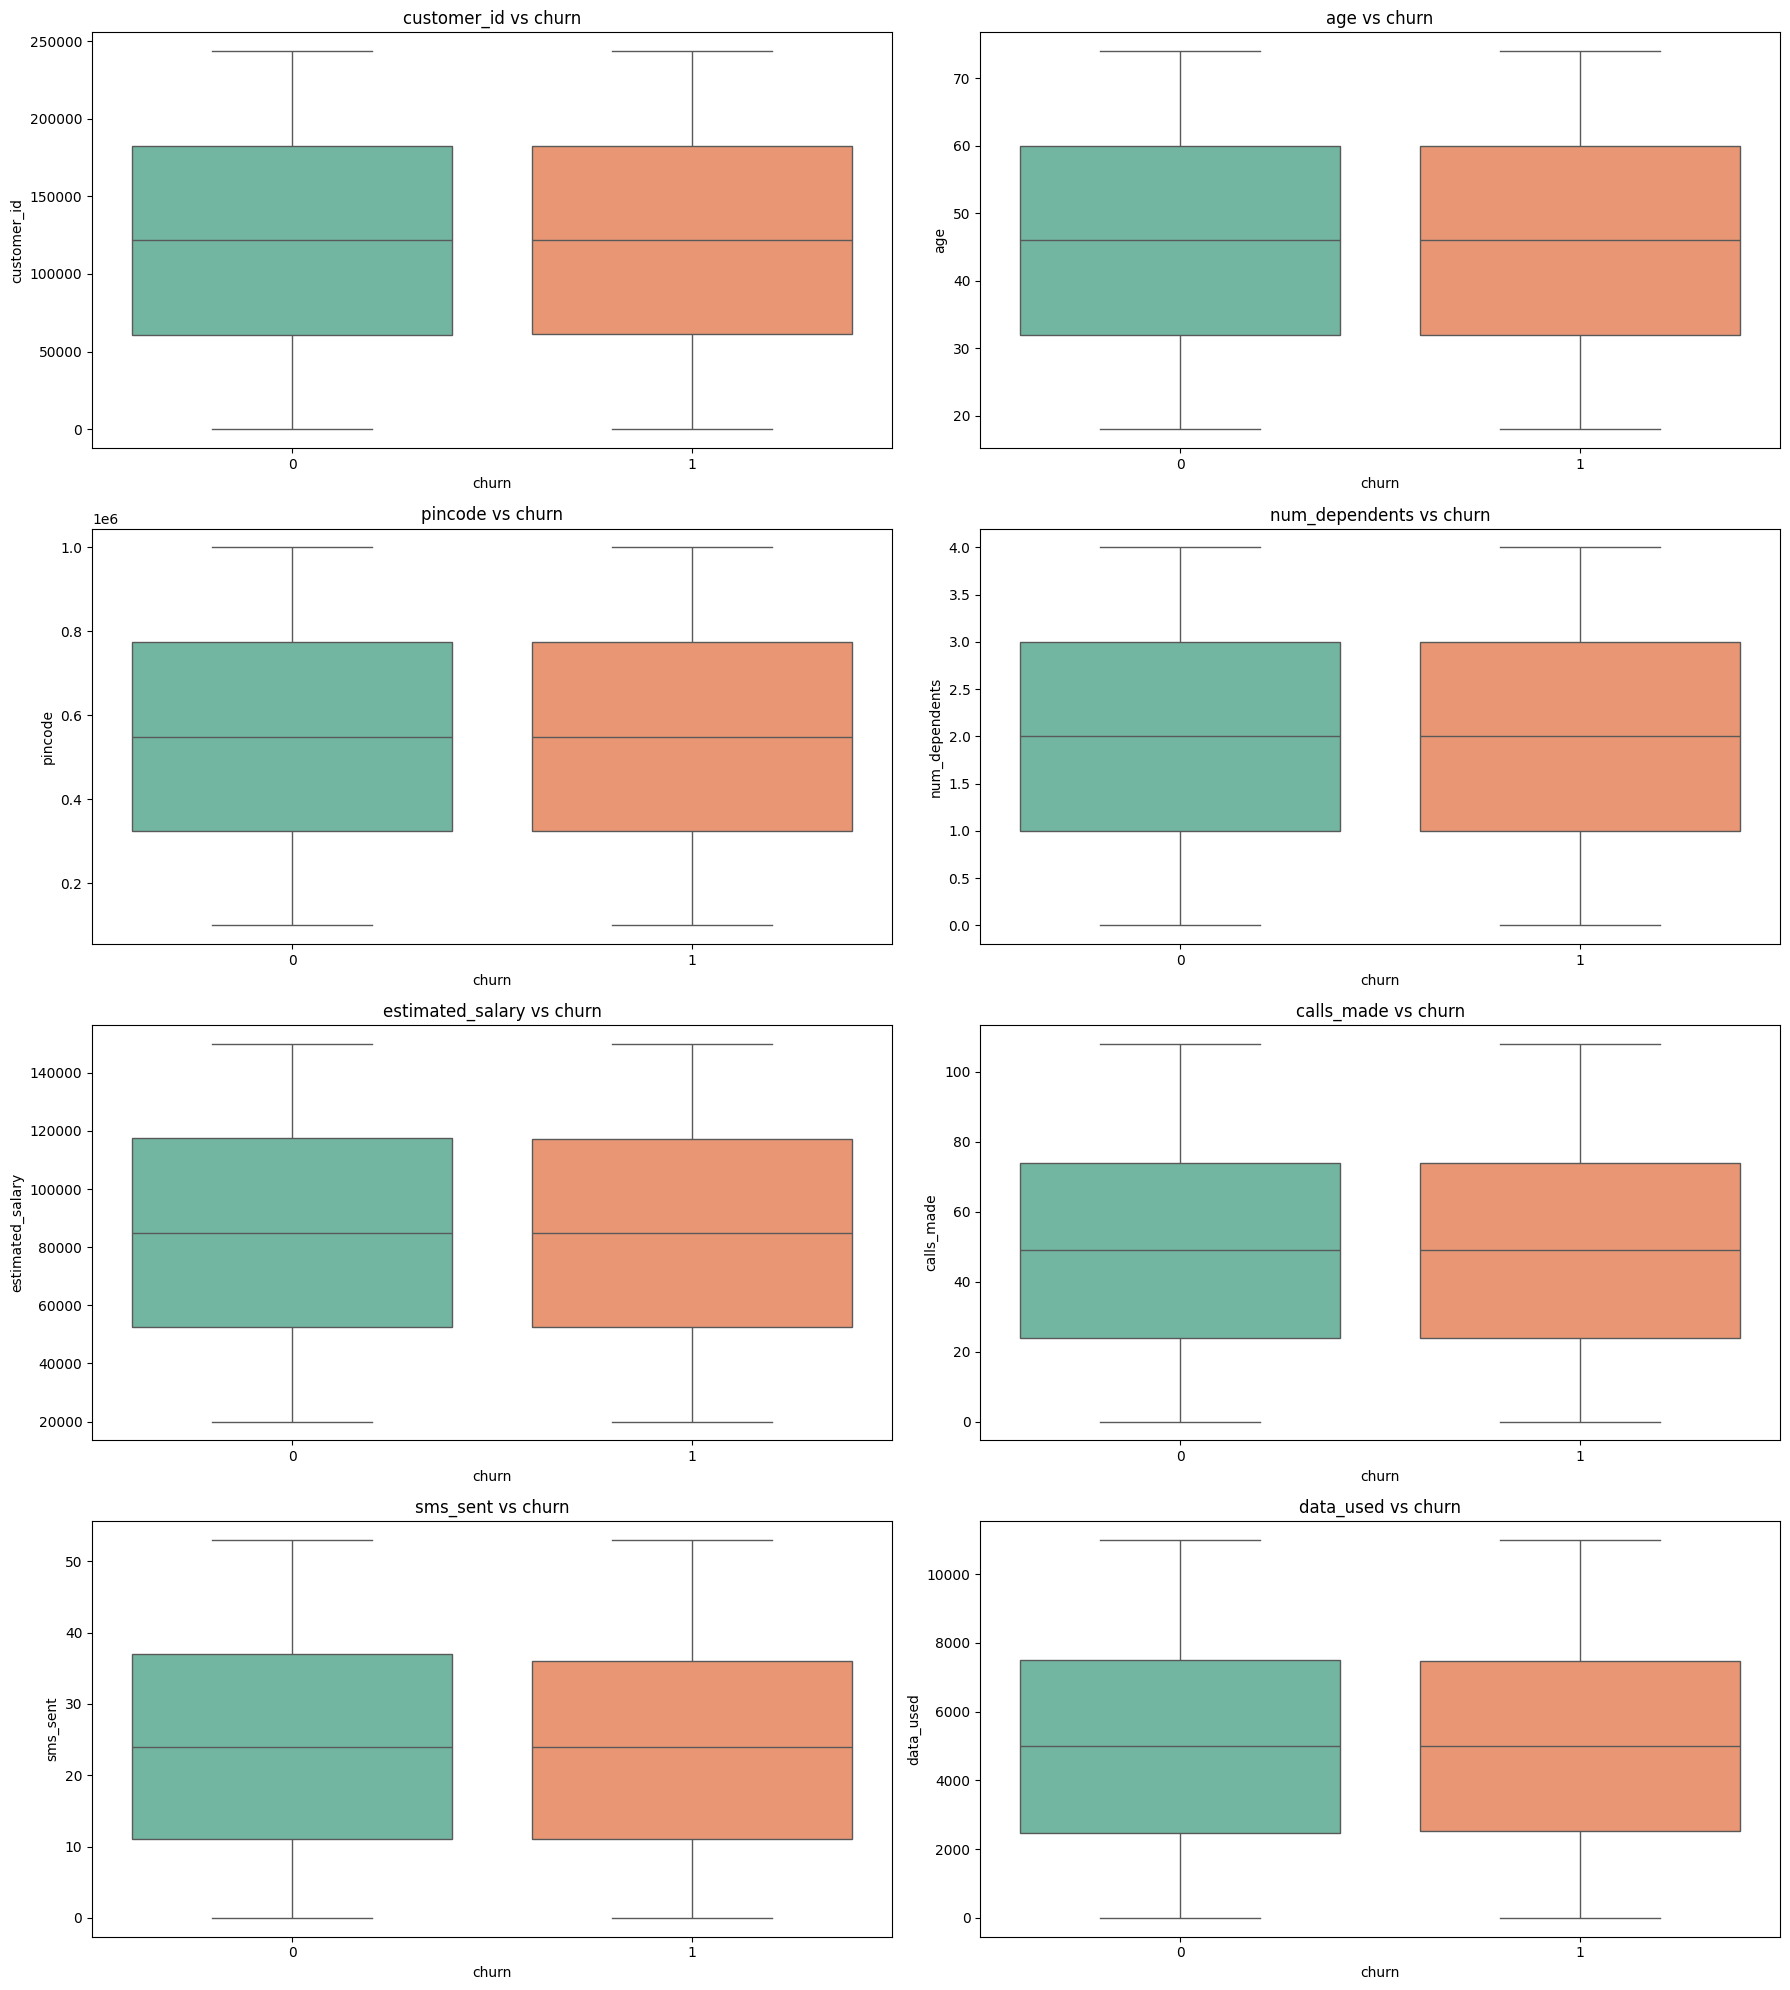

In [ ]:
import math
import warnings

warnings.filterwarnings('ignore')

target = 'churn'
# Exclude 'customer_id' and 'pincode' if we only want behavioral/demographic boxplots,
# or keep all features in num_cols except the target
features_to_plot = [col for col in num_cols if col != target]

n_features = len(features_to_plot)
n_cols_grid = 2
n_rows_grid = math.ceil(n_features / n_cols_grid)

plt.figure(figsize=(18, 5 * n_rows_grid))
for i, col in enumerate(features_to_plot):
    plt.subplot(n_rows_grid, n_cols_grid, i + 1)
    sns.boxplot(x=df[target], y=df[col], palette='Set2')
    plt.title(f"{col} vs {target}")
    plt.xlabel(target)
    plt.ylabel(col)

plt.tight_layout()
plt.show()

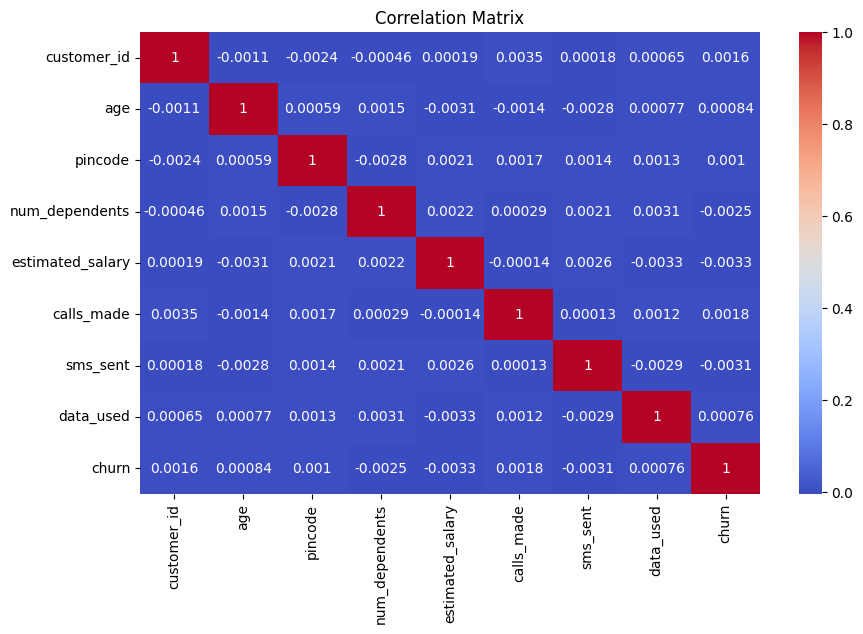


churn               1.000000
calls_made          0.001771
customer_id         0.001649
pincode             0.001019
age                 0.000839
data_used           0.000763
num_dependents     -0.002543
sms_sent           -0.003086
estimated_salary   -0.003332
Name: churn, dtype: float64


In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()
print()

print(df.corr(numeric_only=True)['churn'].sort_values(ascending=False))

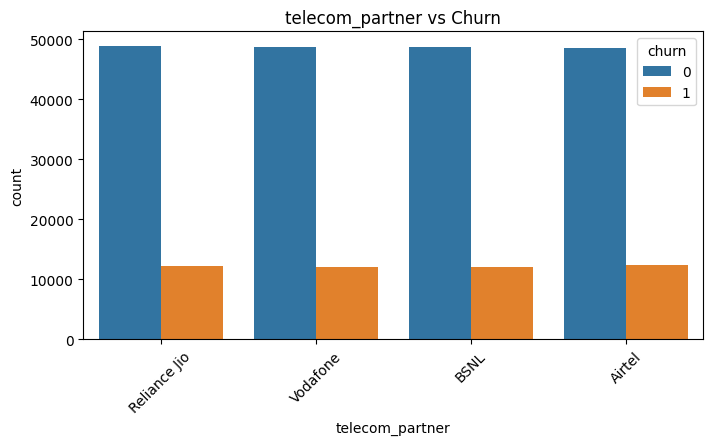

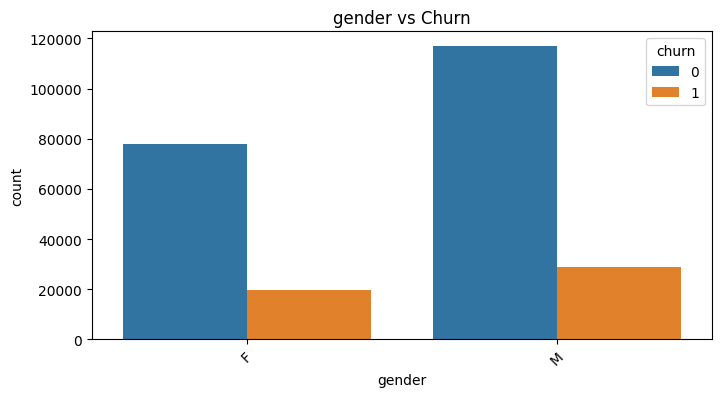

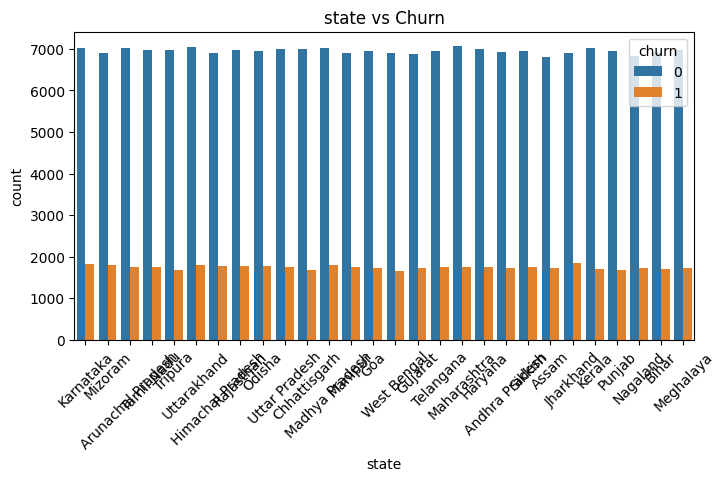

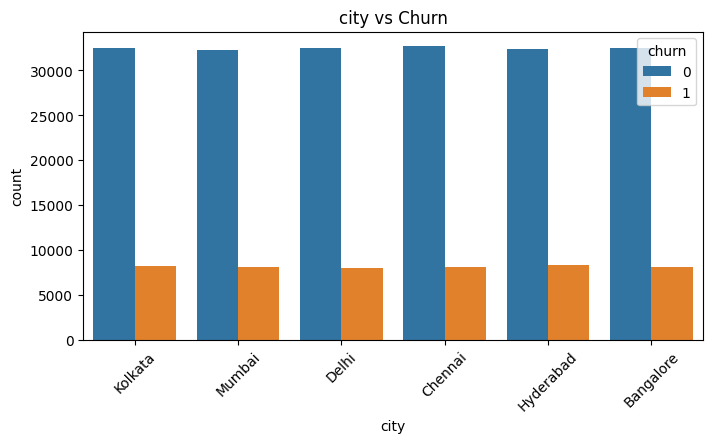

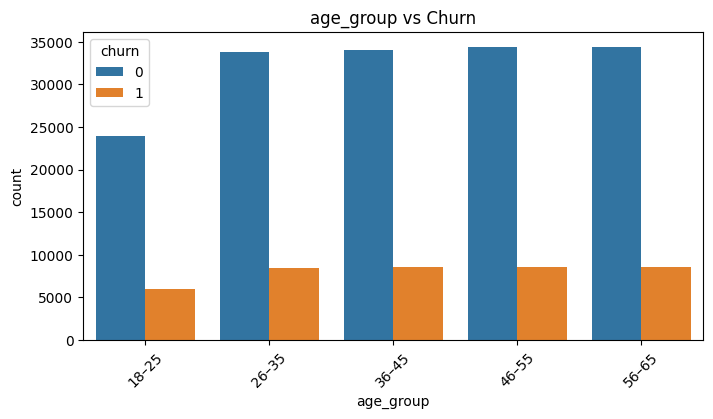

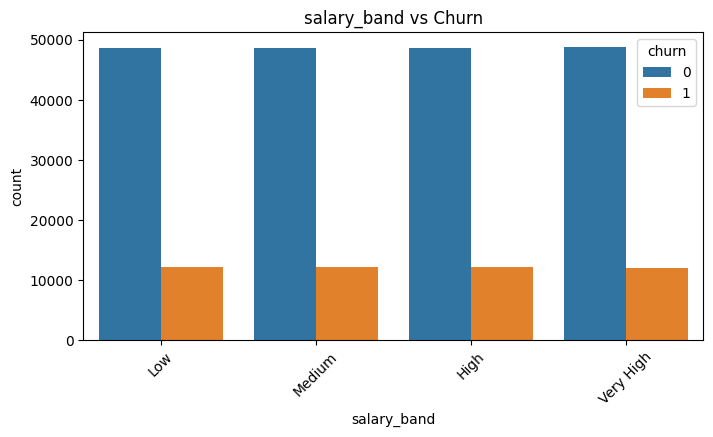

In [ ]:
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

for col in cat_cols:

    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue="churn")
    plt.title(f"{col} vs Churn")
    plt.xticks(rotation=45)
    plt.show()
    print()

In [ ]:
for col in cat_cols:

    churn_percentage = (
        pd.crosstab(
            index=df[col],
            columns=df["churn"],
            normalize="index"
        )
        .mul(100)
        .round(2)
        .rename(columns={0: "Non-Churn (%)", 1: "Churn (%)"})
        .reset_index()
    )

    print(f"\n{col.upper()} CHURN PERCENTAGE")
    print(churn_percentage)


TELECOM_PARTNER CHURN PERCENTAGE
churn telecom_partner  Non-Churn (%)  Churn (%)
0              Airtel          79.63      20.37
1                BSNL          80.14      19.86
2        Reliance Jio          79.98      20.02
3            Vodafone          80.05      19.95

GENDER CHURN PERCENTAGE
churn gender  Non-Churn (%)  Churn (%)
0          F          79.70      20.30
1          M          80.12      19.88

STATE CHURN PERCENTAGE
churn              state  Non-Churn (%)  Churn (%)
0         Andhra Pradesh          80.15      19.85
1      Arunachal Pradesh          80.11      19.89
2                  Assam          79.70      20.30
3                  Bihar          80.37      19.63
4           Chhattisgarh          80.57      19.43
5                    Goa          80.04      19.96
6                Gujarat          79.98      20.02
7                Haryana          79.97      20.03
8       Himachal Pradesh          79.59      20.41
9              Jharkhand          78.88      21.12

####3. Feature Engineering

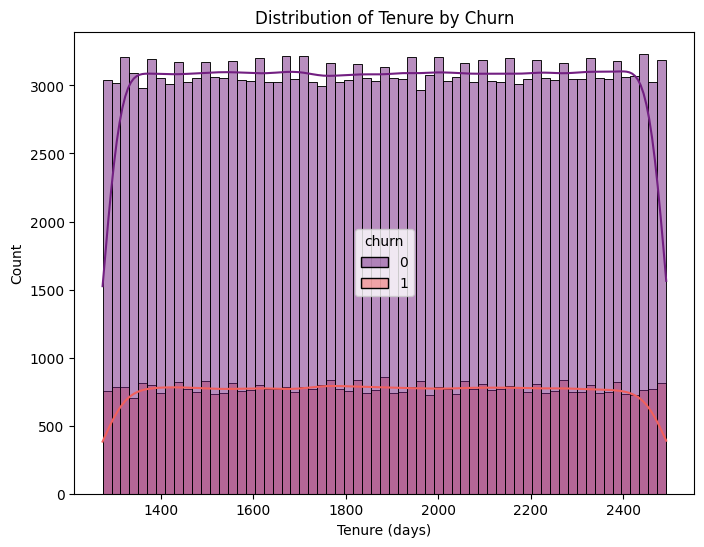


Average tenure for churned customers: 1882.84 days
Average tenure for non-churned customers: 1884.29 days


In [ ]:
df['tenure'] = (pd.to_datetime('today') - df['date_of_registration']).dt.days

plt.figure(figsize=(8, 6))
sns.histplot(data=df, x='tenure', hue='churn', kde=True, palette='magma')
plt.title('Distribution of Tenure by Churn')
plt.xlabel('Tenure (days)')
plt.ylabel('Count')
plt.show()
print()

print(f"Average tenure for churned customers: {df[df['churn'] == 1]['tenure'].mean():.2f} days")
print(f"Average tenure for non-churned customers: {df[df['churn'] == 0]['tenure'].mean():.2f} days")

In [ ]:
cols_to_drop = ['customer_id', 'age_group', 'salary_band', 'pincode', 'date_of_registration']

categorical_cols_for_ohe = ['telecom_partner', 'gender', 'state', 'city']
df_encoded = pd.get_dummies(df, columns=categorical_cols_for_ohe, drop_first=True, dtype=int)
df_model = df_encoded.drop(columns=cols_to_drop, errors='ignore')

print(f"Shape of DataFrame after One-Hot Encoding: {df_encoded.shape}")
print("First 5 rows of encoded DataFrame:")
print(df_model.head())

Shape of DataFrame after One-Hot Encoding: (243553, 49)
First 5 rows of encoded DataFrame:
   age  num_dependents  estimated_salary  calls_made  sms_sent  data_used  \
0   25               4            124962          44        45          0   
1   55               2            130556          62        39       5973   
2   57               0            148828          49        24        193   
3   46               1             38722          80        25       9377   
4   26               2             55098          78        15       1393   

   churn  tenure  telecom_partner_BSNL  telecom_partner_Reliance Jio  ...  \
0      0    2493                     0                             1  ...   
1      0    2493                     0                             1  ...   
2      1    2493                     0                             0  ...   
3      1    2493                     1                             0  ...   
4      0    2493                     1                       

####4. Splitting data

In [ ]:
from sklearn.model_selection import train_test_split

x = df_model.drop('churn', axis=1)
y = df_model['churn']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", x_train.shape)
print("Testing set:", x_test.shape)

Training set: (194842, 43)
Testing set: (48711, 43)


####5. ML model training

>We will train 3 models:
>1. Logistic Regression
2. Decision Tree
3. Random Forest

Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

LogisticRegressionModel = LogisticRegression(max_iter=1000)
LogisticRegressionModel.fit(x_train_scaled, y_train)

y_pred_lr = LogisticRegressionModel.predict(x_test_scaled)
y_prob_lr = LogisticRegressionModel.predict_proba(x_test_scaled)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")
print(f"PR-AUC (Average Precision): "
      f"{average_precision_score(y_test, y_prob_lr):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Accuracy: 0.7995
ROC-AUC: 0.5057
PR-AUC (Average Precision): 0.2050

Confusion Matrix:
[[38946     0]
 [ 9765     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     38946
           1       0.00      0.00      0.00      9765

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



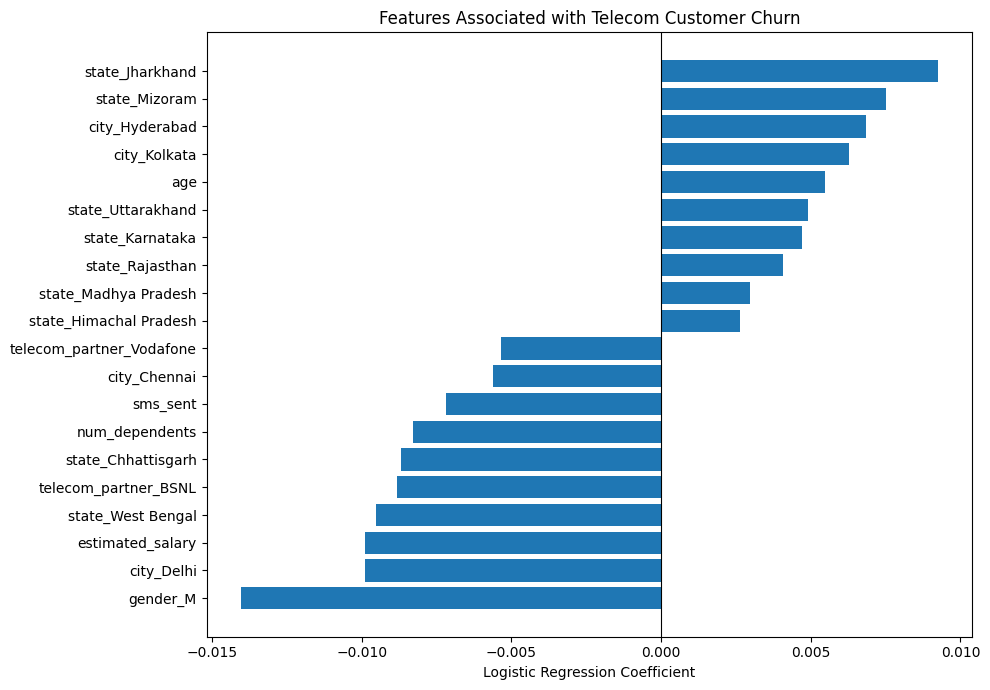

In [ ]:
lr_coefficients = LogisticRegressionModel.coef_[0]

feature_names = x_train.columns

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_coefficients
})

top_positive = coef_df.nlargest(10, "Coefficient")
top_negative = coef_df.nsmallest(10, "Coefficient")

top_features = pd.concat(
    [top_negative, top_positive]
).sort_values("Coefficient")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.title("Features Associated with Telecom Customer Churn")
plt.tight_layout()
plt.show()

Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

DecisionTreeModel = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42
)

DecisionTreeModel.fit(x_train, y_train)

y_pred_dt = DecisionTreeModel.predict(x_test)
y_prob_dt = DecisionTreeModel.predict_proba(x_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_dt):.4f}")
print(f"PR-AUC: {average_precision_score(y_test, y_prob_dt):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Accuracy: 0.4335
ROC-AUC: 0.5008
PR-AUC: 0.2012

Confusion Matrix:
[[15157 23789]
 [ 3805  5960]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.39      0.52     38946
           1       0.20      0.61      0.30      9765

    accuracy                           0.43     48711
   macro avg       0.50      0.50      0.41     48711
weighted avg       0.68      0.43      0.48     48711



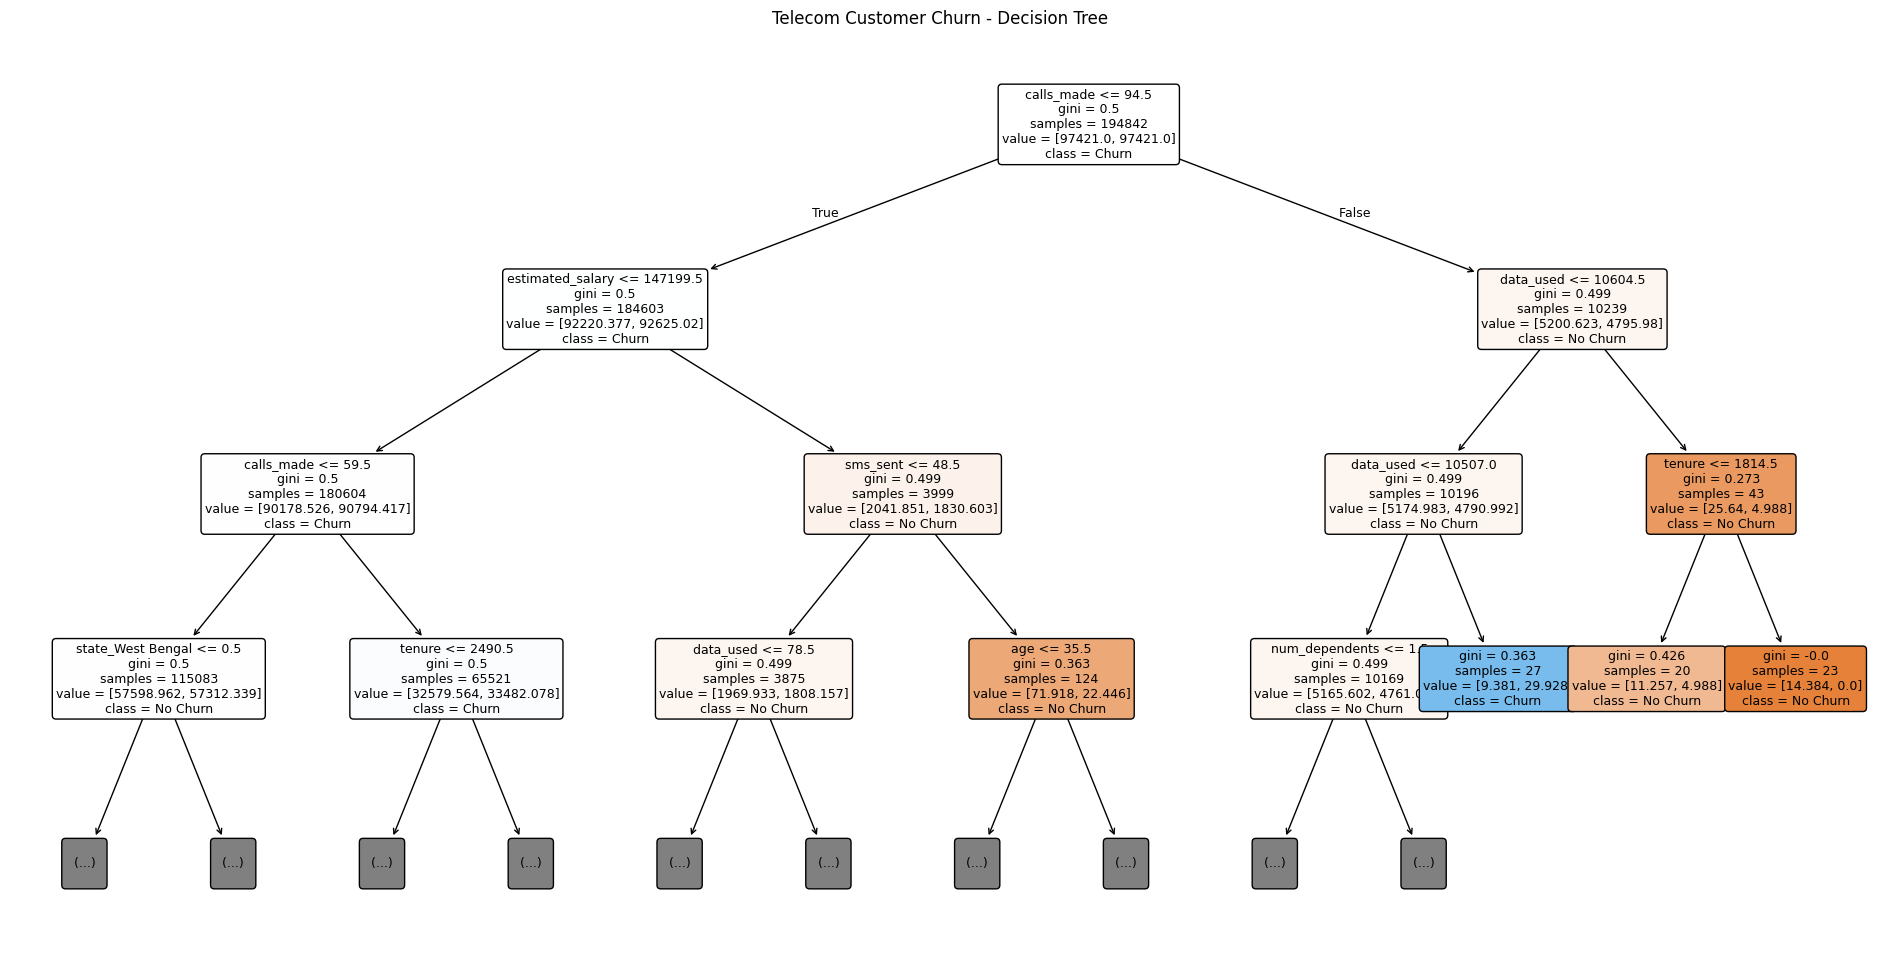

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    DecisionTreeModel,
    feature_names=x_train.columns.tolist(),
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Telecom Customer Churn - Decision Tree")
plt.show()


Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

RandomForestModel = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

RandomForestModel.fit(x_train, y_train)

y_pred_rf = RandomForestModel.predict(x_test)
y_prob_rf = RandomForestModel.predict_proba(x_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"PR-AUC: {average_precision_score(y_test, y_prob_rf):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Accuracy: 0.7219
ROC-AUC: 0.5051
PR-AUC: 0.2041

Confusion Matrix:
[[33823  5123]
 [ 8424  1341]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.87      0.83     38946
           1       0.21      0.14      0.17      9765

    accuracy                           0.72     48711
   macro avg       0.50      0.50      0.50     48711
weighted avg       0.68      0.72      0.70     48711



estimated_salary                0.144857
data_used                       0.140071
tenure                          0.137838
calls_made                      0.119495
sms_sent                        0.108001
age                             0.107229
num_dependents                  0.045565
gender_M                        0.016455
telecom_partner_Reliance Jio    0.014052
telecom_partner_Vodafone        0.013899
telecom_partner_BSNL            0.013581
city_Kolkata                    0.010535
city_Mumbai                     0.010514
city_Hyderabad                  0.010304
city_Chennai                    0.010162
dtype: float64


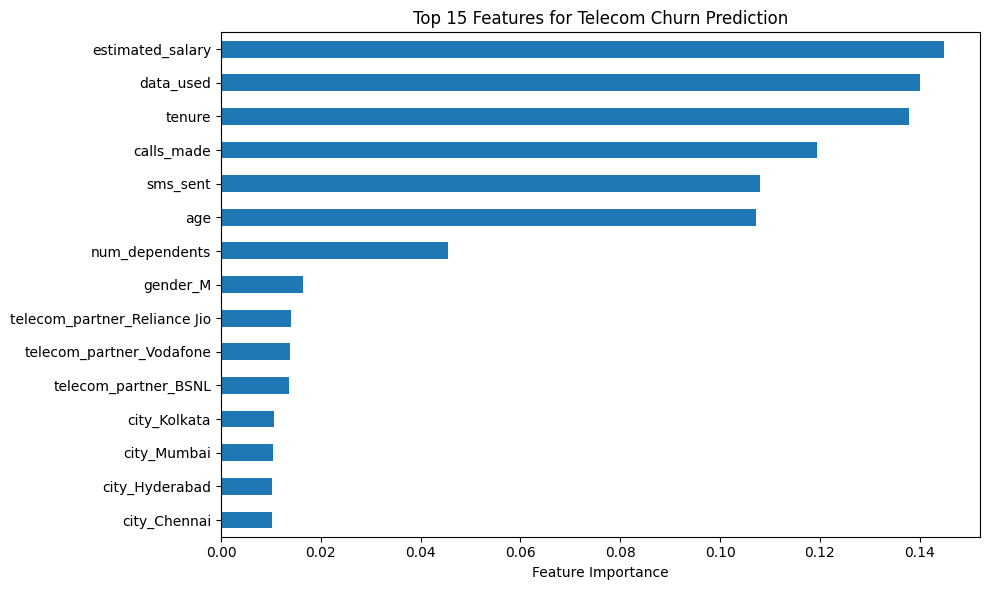

In [ ]:
feature_importance = pd.Series(
    RandomForestModel.feature_importances_,
    index=x_train.columns
).sort_values(ascending=False)

print(feature_importance.head(15))

feature_importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 15 Features for Telecom Churn Prediction")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

####6. Comparision of the models

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Store your fitted models
models = {
    "Logistic Regression": LogisticRegressionModel,
    "Decision Tree": DecisionTreeModel,
    "Random Forest": RandomForestModel
}

results = []

for name, model in models.items():

    # Predicted classes and churn probabilities
    y_pred = model.predict(x_test)
    y_prob = model.predict_proba(x_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

print(results_df.round(4))


                     Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Model                                                                      
Logistic Regression    0.7995     0.0000  0.0000    0.0000   0.4983  0.1998
Decision Tree          0.4335     0.2003  0.6103    0.3017   0.5008  0.2012
Random Forest          0.7219     0.2075  0.1373    0.1653   0.5051  0.2041


In [ ]:

print("Training target distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

print("\nUnique target labels:")
print(y_train.unique())


Training target distribution:
churn
0    155780
1     39062
Name: count, dtype: int64
churn
0    0.79952
1    0.20048
Name: proportion, dtype: float64

Test target distribution:
churn
0    38946
1     9765
Name: count, dtype: int64
churn
0    0.799532
1    0.200468
Name: proportion, dtype: float64

Unique target labels:
[0 1]


####7. Ml model training using SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(
    X_train, y_train
)

# Train on resampled data
model.fit(X_train_smote, y_train_smote)

# Evaluate on the original, untouched test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [ ]:
ratio = np.sum(y_train == 0) / np.sum(y_train == 1)

model_list = [
    ("Logistic Regression", LogisticRegression(max_iter=1000, class_weight='balanced')),
    ("Random Forest", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )),
    ("Decision Tree", DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ))
]

for name, model in model_list:

    # Train
    model.fit(X_train_smote, y_train_smote)

    # Predict
    y_pred = model.predict(x_test)

    # Evaluate
    accuracy = accuracy_score(y_test, y_pred)

    recall = recall_score(y_test, y_pred)

    # Report
    print(f"\n--- {name} Performance ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Recall: {recall:.4f}")
    print(classification_report(y_test, y_pred))
    print("-" * 30)


--- Logistic Regression Performance ---
Accuracy: 0.6763
Recall: 0.2122
              precision    recall  f1-score   support

           0       0.80      0.79      0.80     38946
           1       0.20      0.21      0.21      9765

    accuracy                           0.68     48711
   macro avg       0.50      0.50      0.50     48711
weighted avg       0.68      0.68      0.68     48711

------------------------------

--- Random Forest Performance ---
Accuracy: 0.7418
Recall: 0.0994
              precision    recall  f1-score   support

           0       0.80      0.90      0.85     38946
           1       0.20      0.10      0.13      9765

    accuracy                           0.74     48711
   macro avg       0.50      0.50      0.49     48711
weighted avg       0.68      0.74      0.71     48711

------------------------------

--- Decision Tree Performance ---
Accuracy: 0.6846
Recall: 0.1991
              precision    recall  f1-score   support

           0       0.8

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

ROC-AUC: 0.5068219696004569
PR-AUC: 0.20370195669028157


In [ ]:
import pandas as pd

feature_check = X_train.copy()
feature_check["churn"] = y_train

correlations = (
    feature_check.corr(numeric_only=True)["churn"]
    .drop("churn")
    .sort_values(key=abs, ascending=False)
)

print(correlations.head(20))

gender_M               -0.005588
city_Delhi             -0.004569
estimated_salary       -0.003952
state_West Bengal      -0.003899
state_Jharkhand         0.003839
state_Chhattisgarh     -0.003549
city_Hyderabad          0.003362
num_dependents         -0.003264
city_Kolkata            0.003114
state_Mizoram           0.003109
sms_sent               -0.002911
city_Chennai           -0.002647
telecom_partner_BSNL   -0.002475
age                     0.002173
state_Uttarakhand       0.002061
state_Karnataka         0.001969
tenure                 -0.001895
state_Tripura          -0.001815
state_Kerala           -0.001758
state_Rajasthan         0.001655
Name: churn, dtype: float64
